# Exercício 1

Considere a variável aleatória contínua $X$ com densidade

$$
f(x)=20x(1-x)^3, \qquad 0\leq x\leq 1,
$$

e $f(x)=0$ fora do intervalo $[0,1]$.

1. Utilizando o método de Aceitação-Rejeição (AR), gere uma amostra i.i.d. de tamanho $n$ da distribuição com densidade $f$. Utilize como distribuição proposta uma distribuição Uniforme em $[0,1]$.

   Para determinar a constante $M$ do método de Aceitação-Rejeição, aproxime numericamente o máximo de $f$ no intervalo $[0,1]$. Para isso, construa uma malha suficientemente fina utilizando `np.linspace`, avalie a função $f$ nos pontos dessa malha e utilize `np.max` para obter uma aproximação de

$$
M = \max_{0\leq x\leq 1} f(x).
$$

2. Faça um gráfico contendo a densidade teórica $f(x)$ e o histograma normalizado da amostra gerada. Compare visualmente a distribuição da amostra com a densidade teórica.

3. Para cada observação gerada, registre o número de tentativas necessárias até ocorrer a primeira aceitação.

   a. Determine teoricamente a probabilidade de aceitação do método AR.

   b. Determine o número esperado de tentativas até a primeira aceitação.

   c. Compare a média empírica do número de tentativas com o valor esperado teoricamente.

   d. Determine a distribuição teórica do número de tentativas até a primeira aceitação e compare-a com a distribuição empírica obtida na simulação.

[0.15848902455851488, 0.30834706648987686, 0.179996734865562, 0.7849493104433931, 0.29816341553566694, 0.2930638582704417, 0.6072829703393926, 0.39195511196165866, 0.3193296006123332, 0.5758453290833453, 0.5189666888843124, 0.45313892589143245, 0.33155860545125215, 0.47242618782797374, 0.07066742066730636, 0.28820851225426536, 0.39694897597548917, 0.15358109460336355, 0.4602558376974749, 0.3894132498403854, 0.6343311782374684, 0.07648607598432855, 0.22515186789985653, 0.4019021934983309, 0.5070795354988599, 0.044249858761046146, 0.2828733611079558, 0.5114070191216217, 0.3945520519428486, 0.30062940815138517, 0.3124437544587694, 0.29831382805547557, 0.13353645993550012, 0.2444728536987344, 0.4002806655073544, 0.23436811889688958, 0.24175351838286274, 0.5958888985059305, 0.4423601297080677, 0.4441951294616735, 0.0896848933818214, 0.7370257048885729, 0.4168484607682764, 0.134317246330794, 0.16314505223378795, 0.3852202452185567, 0.3307793681769111, 0.34301818333839784, 0.2925832699655522,

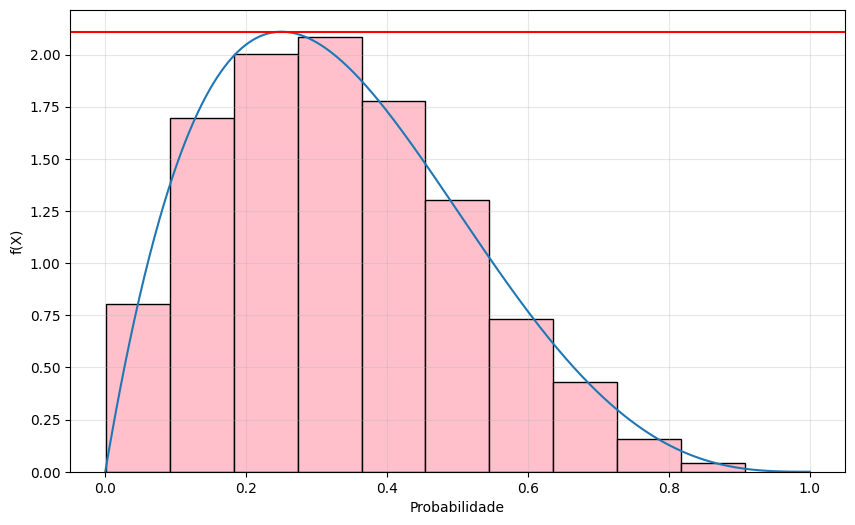

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
  return (20*x*(1-x)**3)

n_amostra = 5000

i = np.linspace(0,1, 1000)
pontos_f = f(i) # normalmente isso seria dividido por g(x), mas como g(x) é U(0,1), seria uma divisão por 1
c = np.max(pontos_f)

tentativas = [] # Número de tentativas até o sucesso

def geraPontoX():
  i = 0
  while True:
    i += 1
    g = np.random.uniform(0,1) # Y ~ dist. auxiliar pra esse exemplo vai ser uma uniforme (0,1)
    if np.random.uniform(0,1) < (f(g)/c):
      tentativas.append(i)
      return g

a = []
for _ in range(n_amostra):
  a.append(geraPontoX())

print(a)

plt.figure(figsize=(10, 6))
plt.hist(a, density=True, color="pink", label="f simulada por rejeição-aceitação", edgecolor='black')
plt.grid(True, alpha=0.3)
plt.plot(i, pontos_f, label="f teórica")
plt.axhline(y=c, color='r', linestyle='-')
plt.xlabel("Probabilidade")
plt.ylabel("f(X)")

plt.show()

# Plot da função para verificar o posicionamento do c
#plt.plot(i, intervalos)
#plt.axhline(y=c, color='r', linestyle='-')


2.1093735915600758
2.1078


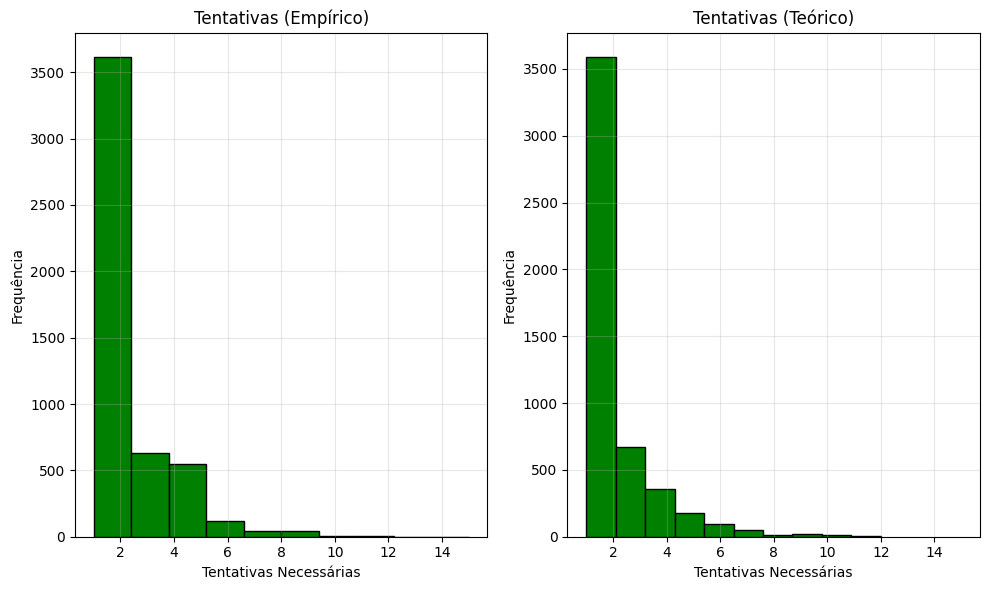

In [ ]:
p_geometrica = 1/c # Parâmetro para dist. geometrica

media_teorica_geometrica = 1/p_geometrica
media_empirica_aceitacao = np.mean(tentativas)

def amostraRecursivaGeometrica(M, p):
  u = np.random.uniform(0,1, size = M)
  return (np.floor(np.log(1 - u)/np.log(1 - p)) + 1)

geometrica_tentativas = amostraRecursivaGeometrica(n_amostra, p_geometrica) #posso usar o numpy?

print(media_teorica_geometrica)
print(media_empirica_aceitacao)

fig, axs = plt.subplots(1, 2, tight_layout=True, sharex=True, figsize=(10, 6)) # https://matplotlib.org/stable/gallery/statistics/hist.html

axs[0].hist(tentativas, color="green", edgecolor='black')
axs[0].set(title="Tentativas (Empírico)")
axs[0].set(xlabel="Tentativas Necessárias")
axs[0].set(ylabel="Frequência")

axs[1].hist(geometrica_tentativas, color="green", edgecolor='black')
axs[1].set(title="Tentativas (Teórico)")
axs[1].set(xlabel="Tentativas Necessárias")
axs[1].set(ylabel="Frequência")

axs[0].grid(True, alpha=0.3)
axs[1].grid(True, alpha=0.3)

plt.show()